# Homework 1 — Linear algebra and data processing

Original joint coursework: **Raha Sajed (credited as Fatemeh Sajed) and Aylar Rahimzadeh**. Post-course corrections: **Raha Sajed (`raha-sajed`)**.

This notebook follows [the assignment](AI4032_HW1.pdf). This notebook completes the linear algebra, CWRU signal processing and Iris exercises in the assignment.

# 1. Linear algebra

## I-a. Matrix dimensions

The assignment gives $A\in\mathbb{R}^{2\times3}$ and $B\in\mathbb{R}^{4\times2}$.
A product $(m\times k)(k\times p)$ is defined only when its inner dimensions agree; its shape is $m\times p$. A transpose swaps rows and columns.

| Expression | Dimension check | Answer |
| --- | --- | --- |
| $BA$ | $(4\times2)(2\times3)$ | Defined: $4\times3$ |
| $B^T$ | Transpose of $4\times2$ | $2\times4$ |
| $B^TA$ | $(2\times4)(2\times3)$; $4\ne2$ | Undefined |
| $A^TB$ | $(3\times2)(4\times2)$; $2\ne4$ | Undefined |

**Correction:** reshaping a matrix to make a product run changes the matrix and the problem. The undefined products must remain undefined.

## I-b. Compute the defined expressions

For $i=1,\ldots,4$ and $j=1,\ldots,3$,
$$(BA)_{ij}=b_{i1}a_{1j}+b_{i2}a_{2j}.$$

$$BA=\begin{bmatrix}
b_{11}a_{11}+b_{12}a_{21}&b_{11}a_{12}+b_{12}a_{22}&b_{11}a_{13}+b_{12}a_{23}\\
b_{21}a_{11}+b_{22}a_{21}&b_{21}a_{12}+b_{22}a_{22}&b_{21}a_{13}+b_{22}a_{23}\\
b_{31}a_{11}+b_{32}a_{21}&b_{31}a_{12}+b_{32}a_{22}&b_{31}a_{13}+b_{32}a_{23}\\
b_{41}a_{11}+b_{42}a_{21}&b_{41}a_{12}+b_{42}a_{22}&b_{41}a_{13}+b_{42}a_{23}
\end{bmatrix}.$$

$$B^T=\begin{bmatrix}b_{11}&b_{21}&b_{31}&b_{41}\\b_{12}&b_{22}&b_{32}&b_{42}\end{bmatrix}.$$

There is no value to calculate for $B^TA$ or $A^TB$ with the given matrices. The numerical example below uses the same illustrative values as the original report; the symbolic answer above applies to arbitrary entries.

In [1]:
import numpy as np

A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2], [3, 1], [4, 5], [6, 7]])
BA = B @ A
BT = B.T
np.testing.assert_array_equal(BA, [[9, 12, 15], [7, 11, 15], [24, 33, 42], [34, 47, 60]])
np.testing.assert_array_equal(BT, [[1, 3, 4, 6], [2, 1, 5, 7]])
assert BA.shape == (4, 3) and BT.shape == (2, 4)
print("BA =\n", BA)
print("B transpose =\n", BT)
for name, left, right in [("B.T @ A", B.T, A), ("A.T @ B", A.T, B)]:
    try:
        left @ right
    except ValueError:
        print(f"{name}: undefined ({left.shape[1]} != {right.shape[0]})")
    else:
        raise AssertionError(f"{name} should be undefined")

BA =
 [[ 9 12 15]
 [ 7 11 15]
 [24 33 42]
 [34 47 60]]
B transpose =
 [[1 3 4 6]
 [2 1 5 7]]
B.T @ A: undefined (4 != 2)
A.T @ B: undefined (2 != 4)


## II-a. Row-vector and matrix predictions

A sample $x^{(i)}=[x_1^{(i)}\;x_2^{(i)}]$ has shape $1\times2$, and
$\theta=[\theta_1\;\theta_2]^T$ has shape $2\times1$. Therefore
$$x^{(i)}\theta=x_1^{(i)}\theta_1+x_2^{(i)}\theta_2\in\mathbb{R}^{1\times1}.$$

Stacking $n$ samples gives $X\in\mathbb{R}^{n\times2}$ and
$$X\theta=\begin{bmatrix}x_1^{(1)}\theta_1+x_2^{(1)}\theta_2\\\vdots\\x_1^{(n)}\theta_1+x_2^{(n)}\theta_2\end{bmatrix}\in\mathbb{R}^{n\times1}.$$

In NumPy, `X[i:i+1]` keeps a sample as a row matrix; `X[i]` produces a one-dimensional array. Column-shaped targets also prevent unintended broadcasting.

In [2]:
X = np.array([[1., 1.], [1., 2.], [1., 3.]])
theta = np.array([[0.5], [1.5]])
y = np.array([[2.], [4.], [6.]])
x_i = X[0:1]
assert x_i.shape == (1, 2) and theta.shape == (2, 1)
assert (x_i @ theta).shape == (1, 1)
assert (X @ theta).shape == (3, 1)
print("One sample prediction:", x_i @ theta, "shape:", (x_i @ theta).shape)
print("All predictions:\n", X @ theta, "shape:", (X @ theta).shape)

One sample prediction: [[2.]] shape: (1, 1)
All predictions:
 [[2. ]
 [3.5]
 [5. ]] shape: (3, 1)


## II-b. Vector form of the loss and its gradient

Let $y\in\mathbb{R}^{n\times1}$ and $r=X\theta-y$. The assignment uses the **sum** of squared errors:
$$J(\theta)=\sum_{i=1}^{n}(x^{(i)}\theta-y^{(i)})^2=r^Tr=(X\theta-y)^T(X\theta-y).$$
This is a scalar ($1\times1$). Expanding it gives
$$J=\theta^TX^TX\theta-2\theta^TX^Ty+y^Ty.$$
Since $X^TX$ is symmetric and $X,y$ do not depend on $\theta$,
$$\boxed{\nabla_\theta J=2X^TX\theta-2X^Ty=2X^T(X\theta-y)}\in\mathbb{R}^{2\times1}.$$

Equivalently, for $j\in\{1,2\}$,
$$\frac{\partial J}{\partial\theta_j}=2\sum_{i=1}^{n}x_j^{(i)}\bigl(x^{(i)}\theta-y^{(i)}\bigr).$$

**Correction:** the gradient must be evaluated, not left as an unevaluated derivative. There is no $1/n$ in this assignment's loss. Using MSE instead would divide this gradient by $n$; using $J/(2n)$ would give $X^Tr/n$.

In [3]:
def squared_error_and_gradient(X, theta, y):
    """Sum of squared errors; use explicit column vectors to avoid broadcasting."""
    X, theta, y = (np.asarray(value, dtype=float) for value in (X, theta, y))
    if X.ndim != 2 or theta.shape != (X.shape[1], 1) or y.shape != (X.shape[0], 1):
        raise ValueError("Expected X: (n, p), theta: (p, 1), y: (n, 1)")
    residual = X @ theta - y
    return float((residual.T @ residual).item()), 2 * X.T @ residual

J, gradient = squared_error_and_gradient(X, theta, y)
np.testing.assert_allclose(J, 1.25)
np.testing.assert_allclose(gradient, [[-3.], [-8.]])
np.testing.assert_allclose(J, sum(float((row @ theta).item() - target.item()) ** 2 for row, target in zip(X, y)))
print("J =", J)
print("Gradient =\n", gradient, "shape:", gradient.shape)

J = 1.25
Gradient =
 [[-3.]
 [-8.]] shape: (2, 1)


## Numerical verification

A central finite-difference approximation checks each partial derivative independently of the matrix-gradient formula. We test several data sizes and parameter values, plus a malformed target shape that would otherwise broadcast silently.

In [4]:
rng = np.random.default_rng(42)
max_absolute_error = 0.0
for n in (1, 3, 10):
    X_check = rng.normal(size=(n, 2))
    theta_check = rng.normal(size=(2, 1))
    y_check = rng.normal(size=(n, 1))
    loss, analytic = squared_error_and_gradient(X_check, theta_check, y_check)
    numeric = np.zeros_like(theta_check)
    epsilon = 1e-6
    for j in range(2):
        step = np.zeros_like(theta_check)
        step[j, 0] = epsilon
        plus, _ = squared_error_and_gradient(X_check, theta_check + step, y_check)
        minus, _ = squared_error_and_gradient(X_check, theta_check - step, y_check)
        numeric[j, 0] = (plus - minus) / (2 * epsilon)
    np.testing.assert_allclose(analytic, numeric, rtol=1e-6, atol=1e-6)
    max_absolute_error = max(max_absolute_error, float(np.max(np.abs(analytic - numeric))))
try:
    squared_error_and_gradient(X, theta, y.ravel())
except ValueError:
    pass
else:
    raise AssertionError("A one-dimensional target must be rejected")
print("All dimension, product, loss and gradient checks passed.")
print(f"Maximum absolute finite-difference error: {max_absolute_error:.2e}")

All dimension, product, loss and gradient checks passed.
Maximum absolute finite-difference error: 8.76e-10


# 2. Data processing — CWRU signal

## I-a. Read the MAT file and identify its contents

The input is a MATLAB `.mat` file. `scipy.io.loadmat` returns a dictionary: `__header__`, `__version__` and `__globals__` describe the MAT container; the other entries hold measurements. `DE` and `FE` identify drive-end and fan-end accelerometer signals; `RPM` is motor speed. We select `X201_DE_time` without changing its samples.

The assignment specifies **48 kHz**. The [CWRU 48k table](https://engineering.case.edu/bearingdatacenter/48k-drive-end-bearing-fault-data) links `201.mat` as the outer-race, 0.014-inch, zero-load case. [CWRU variable naming](https://engineering.case.edu/bearingdatacenter/download-data-file) explains the channel names.

In [5]:
from pathlib import Path
import sys
import pandas as pd
from scipy.io import loadmat
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "HomeWork1" / "201.mat").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from HomeWork1.signal_analysis import (
    HERE, run, compute_spectrum, segment_signal, extract_features,
    signal_statistics, time_window,
)
payload = loadmat(HERE / "201.mat")
print("Container type:", type(payload).__name__)
display(pd.DataFrame([
    {"field": name, "type": type(value).__name__, "shape": getattr(value, "shape", None)}
    for name, value in payload.items()
]))
signal = payload["X201_DE_time"].reshape(-1)
fs = 48_000.
print("Selected channel:", "X201_DE_time", "samples:", len(signal))
print("Recorded motor speed (RPM):", int(payload["X201RPM"].item()))

Container type: dict
Selected channel: X201_DE_time samples: 245140
Recorded motor speed (RPM): 1796


,field,type,shape
0,__header__,bytes,None
1,__version__,str,None
2,__globals__,list,None
3,X201_DE_time,ndarray,"(245140, 1)"
4,X201_FE_time,ndarray,"(245140, 1)"
5,X201RPM,ndarray,"(1, 1)"


## I-b. Plot the signal in seconds

Use $t_k=k/f_s$ with $f_s=48,000$ Hz. Plot the entire recording, then the requested interval $[2.00,2.01)$ seconds. The interval is half-open to avoid duplicating a boundary sample. We retain every original sample; taking every second sample without adjusting the time vector would distort the time axis.

{
  "n_samples": 245140,
  "sampling_rate_hz": 48000.0,
  "zoom_samples": 480,
  "n_windows": 3829,
  "dominant_frequency_hz": 0.19580647793097825,
  "all_features_finite": true
}
Recording duration: 5.107083 seconds; zoom samples: 480


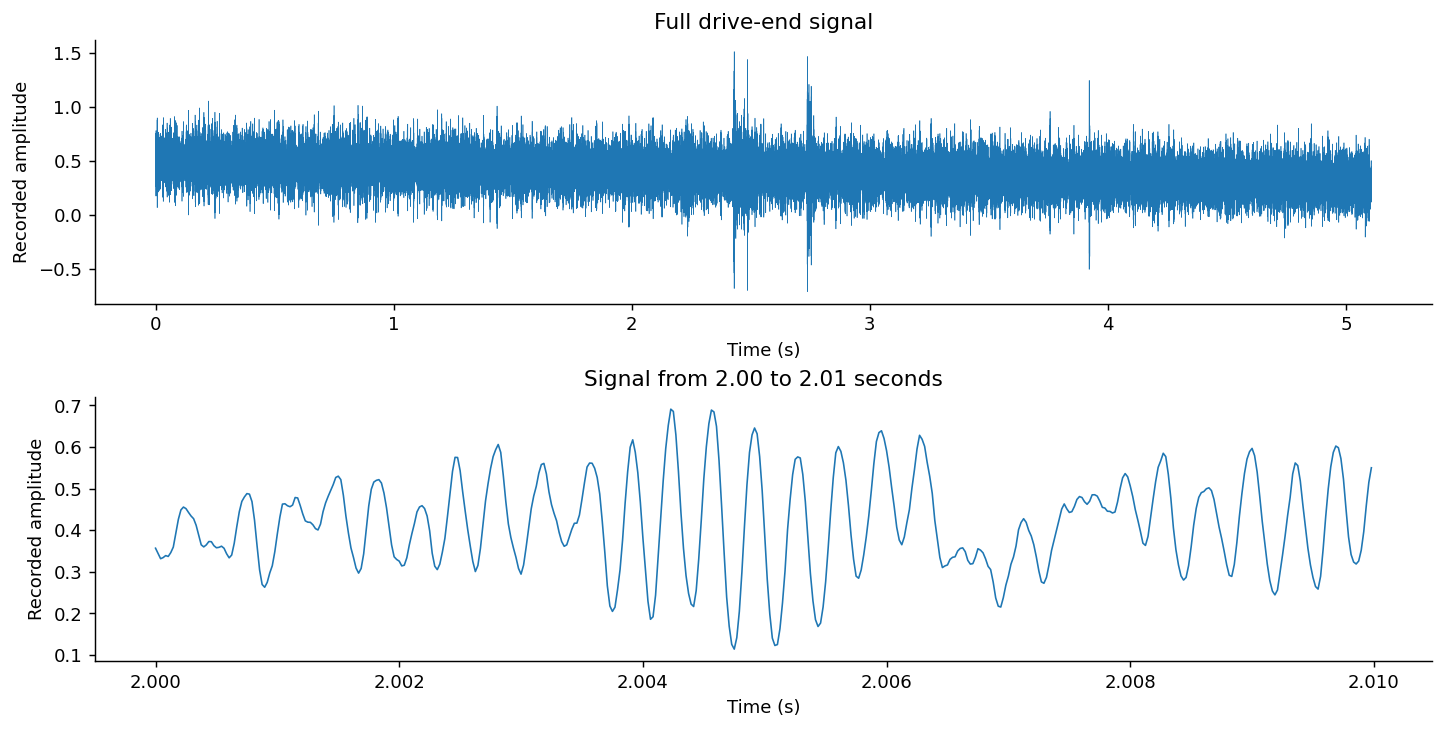

In [6]:
import io
import matplotlib.pyplot as plt

def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

summary = run(HERE / "201.mat", HERE / "results", sampling_rate=fs)
time = np.arange(len(signal)) / fs
zoom_time, zoom_signal = time_window(signal, fs, 2., 2.01)
assert len(zoom_signal) == 480
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), layout="constrained")
axes[0].plot(time, signal, linewidth=.35)
axes[0].set(title="Full drive-end signal", xlabel="Time (s)", ylabel="Recorded amplitude")
axes[1].plot(zoom_time, zoom_signal, linewidth=.9)
axes[1].set(title="Signal from 2.00 to 2.01 seconds", xlabel="Time (s)", ylabel="Recorded amplitude")
show_figure(fig)
print(f"Recording duration: {len(signal)/fs:.6f} seconds; zoom samples: {len(zoom_signal)}")

## I-c. Frequency spectrum and dominant frequency

`compute_spectrum(signal, fs)` subtracts the global mean for the FFT, calculates a one-sided amplitude spectrum and finds the largest non-DC bin. Positive-frequency amplitudes are doubled except the Nyquist bin for an even-length signal. The frequency spacing is $\Delta f=f_s/N$; the reported peak is a bin estimate, not a sub-bin fitted frequency.

Mean removal applies to the FFT only. Segments and statistical features below use the original signal.

Dominant non-DC FFT bin: 0.196 Hz
FFT bin spacing: 0.195806 Hz


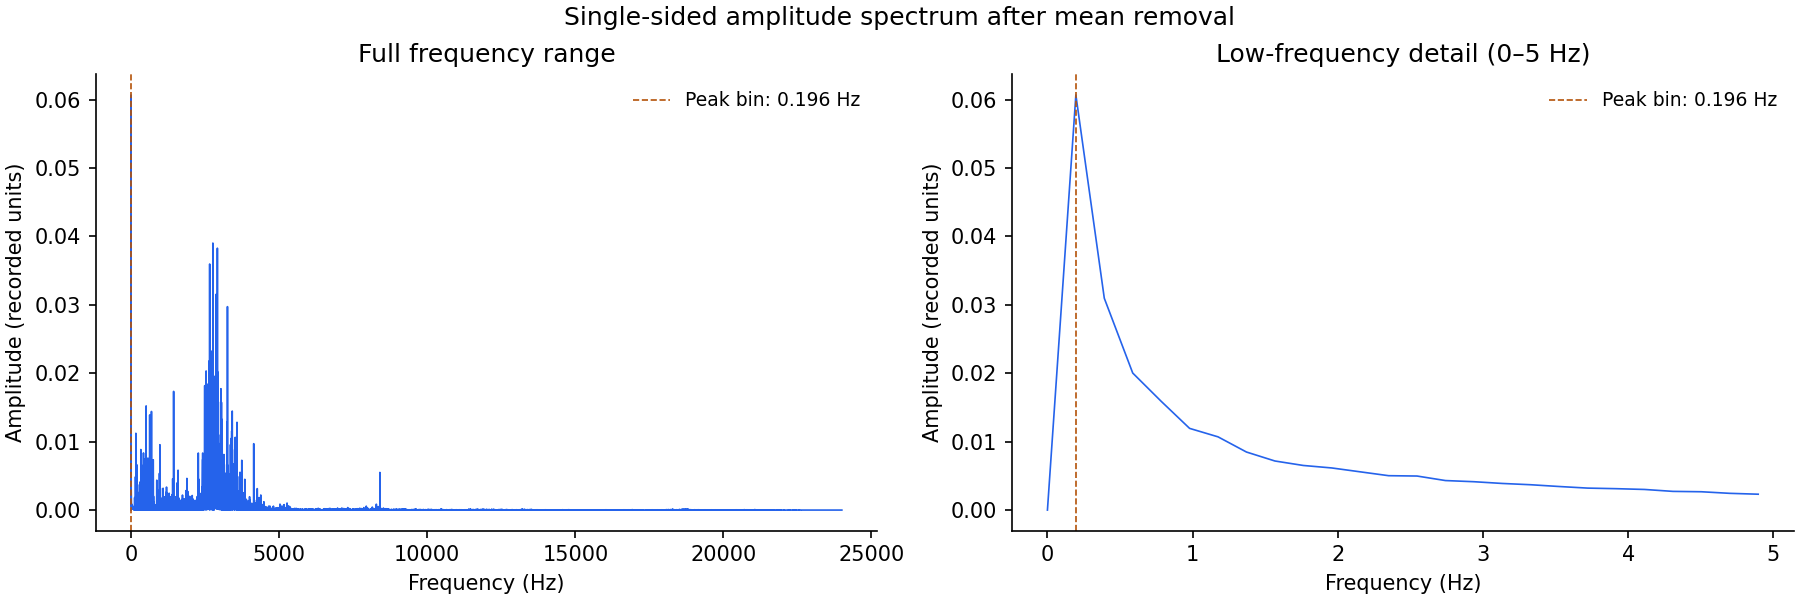

In [7]:
frequency, amplitude, dominant_hz = compute_spectrum(signal, fs)
assert dominant_hz == summary["dominant_frequency_hz"]
print(f"Dominant non-DC FFT bin: {dominant_hz:.3f} Hz")
print(f"FFT bin spacing: {fs/len(signal):.6f} Hz")
display(Image(filename=str(HERE / "results/frequency_spectrum.png")))

## I-d. Divide the signal into windows

Use 128 samples per window and choose 64 samples of overlap. Each row of the NumPy array is one window; the hop is 64 samples. Complete windows number
$$1+\left\lfloor\frac{N-128}{64}\right\rfloor=3829.$$
The final 20 samples cannot form another complete window and are left out.

In [8]:
windows, starts = segment_signal(signal, length=128, overlap=64)
assert windows.shape == (3829, 128)
assert np.array_equal(windows[0], signal[:128])
assert np.array_equal(windows[1], signal[64:192])
print("Window array shape:", windows.shape)
print("Unused tail samples:", len(signal) - (starts[-1] + 128))

Window array shape: (3829, 128)
Unused tail samples: 20


## I-e. DataFrame and ten segment overlays

Create a DataFrame with one segment per row. Select zero-based rows 13, 26, ..., 130: ten positive multiples of 13. A single `for` loop plots these rows with different colors and labels. Time within a segment is measured from that segment's start.

DataFrame shape: (3829, 128) selected rows: [13, 26, 39, 52, 65, 78, 91, 104, 117, 130]


,0,1,2,3,4,5,6,7
0,0.609157,0.675914,0.730988,0.755605,0.736204,0.676748,0.600186,0.512568
1,0.334202,0.391154,0.455199,0.511316,0.550536,0.565556,0.549702,0.515489
2,0.399290,0.426827,0.461666,0.506518,0.565348,0.617919,0.673202,0.701991


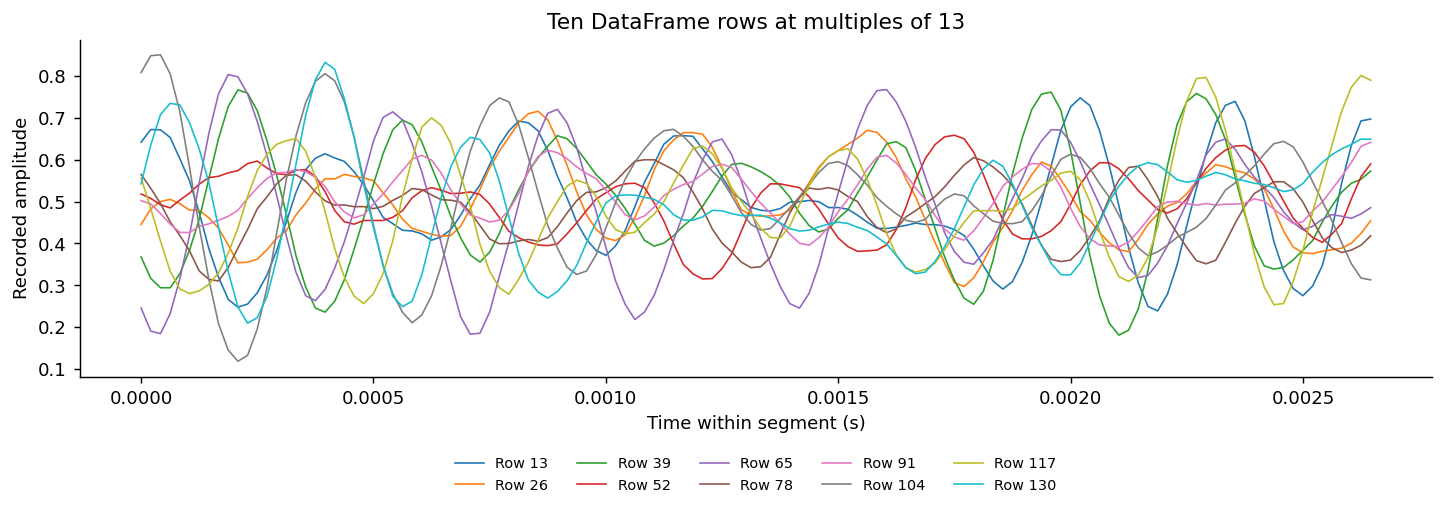

In [9]:
segments = pd.DataFrame(windows)
display(segments.iloc[:3, :8])
selected_rows = np.arange(13, 131, 13)
fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
colors = plt.get_cmap("tab10")
for color_index, row_index in enumerate(selected_rows):
    ax.plot(np.arange(128)/fs, segments.iloc[row_index].to_numpy(),
            color=colors(color_index), label=f"Row {row_index}", linewidth=.9)
ax.set(title="Ten DataFrame rows at multiples of 13", xlabel="Time within segment (s)", ylabel="Recorded amplitude")
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.2))
show_figure(fig)
print("DataFrame shape:", segments.shape, "selected rows:", selected_rows.tolist())

## I-f. Extract features and export CSV

For one signal window $s$ of length $L$, `signal_statistics` returns
$$\mu=\frac1L\sum_k s_k,\qquad \sigma=\sqrt{\frac1L\sum_k(s_k-\mu)^2},\qquad \mathrm{RMS}=\sqrt{\frac1L\sum_k s_k^2}.$$

We use population standard deviation (`ddof=0`) and apply the function to every original, uncentered window. `segment_features.csv` contains **only** the feature columns `mean`, `std`, `rms`, with a header and without a sample/index column.

In [10]:
features = extract_features(windows)
features.to_csv(HERE / "results/segment_features.csv", index=False, float_format="%.10g")
exported = pd.read_csv(HERE / "results/segment_features.csv")
assert exported.shape == (3829, 3)
assert exported.columns.tolist() == ["mean", "std", "rms"]
np.testing.assert_allclose(exported.to_numpy(), features.to_numpy(), rtol=1e-8, atol=1e-10)
np.testing.assert_allclose(features.rms**2, features["std"]**2 + features["mean"]**2)
display(features.head())
display(features.describe())
print("CSV verified:", exported.shape, "columns:", exported.columns.tolist())

CSV verified: (3829, 3) columns: ['mean', 'std', 'rms']


,mean,std,rms
0,0.498770,0.151039,0.521138
1,0.498372,0.146235,0.519384
2,0.506720,0.113735,0.519327
3,0.504900,0.094127,0.513599
4,0.494852,0.191406,0.530579


,mean,std,rms
count,3829.000000,3829.000000,3829.000000
mean,0.396057,0.132965,0.420068
std,0.056368,0.044321,0.056788
min,0.283683,0.046022,0.296872
25%,0.347213,0.105378,0.373306
50%,0.392746,0.126204,0.418054
75%,0.443008,0.152206,0.464570
max,0.521102,0.649391,0.751479


## Signal results

The largest non-DC FFT bin is approximately **0.196 Hz**, equal to the bin spacing for this approximately 5.107-second recording. This indicates strong slow variation in the recording, not an identified bearing-fault frequency. The low-frequency panel shows this peak clearly.

The notebook covers MAT loading, field descriptions, full and zoomed time plots, FFT and its dominant frequency, 128-sample segmentation, the required DataFrame overlay, and three-feature CSV export. The raw recording is preserved. This is descriptive signal processing; the spectral peak alone is not a bearing-fault diagnosis.

# 3. Iris data analysis

## II-a. Dataset and training/test DataFrames

The Iris dataset bundled with scikit-learn contains **150 observations**, **four numerical measurements in centimetres**, and **three flower species**: setosa, versicolor and virginica, with 50 observations each. Sepals and petals are measured by length and width. Species is a categorical label, not another continuous measurement.

Source: the description returned by `sklearn.datasets.load_iris`, citing Fisher (1936), *The use of multiple measurements in taxonomic problems*. We use scikit-learn's bundled version consistently; no external download is needed.

The exercise asks for exploration, not training a classifier. We choose an 80/20 stratified split with `random_state=42` for this portfolio revision, retaining 40 training and 10 test observations of each species. Original sample indices identify observations; a `split` column identifies the two subsets after recombination.

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import seaborn as sns

iris = load_iris(as_frame=True)
feature_cols = iris.feature_names
iris_features = iris.data.copy()
iris_features.index.name = "sample_id"
train_ids, test_ids = train_test_split(
    iris_features.index.to_numpy(), test_size=0.2,
    random_state=42, stratify=iris.target.to_numpy(),
)

def make_iris_frame(sample_ids, split):
    frame = iris_features.loc[sample_ids].copy()
    frame["target"] = iris.target.loc[sample_ids].to_numpy()
    frame["species"] = frame["target"].map(dict(enumerate(iris.target_names)))
    frame["split"] = split
    return frame

iris_train = make_iris_frame(train_ids, "train")
iris_test = make_iris_frame(test_ids, "test")
iris_all = pd.concat([iris_train, iris_test]).sort_index()
assert len(iris_train) == 120 and len(iris_test) == 30
assert set(train_ids).isdisjoint(test_ids)
assert iris_all.index.is_unique and len(iris_all) == 150
assert not iris_all.isna().any().any()
pd.testing.assert_frame_equal(iris_all[feature_cols], iris_features)
class_counts = pd.crosstab(iris_all.species, iris_all.split)
assert class_counts["train"].eq(40).all() and class_counts["test"].eq(10).all()
display(iris_train.head())
display(iris_test.head())
display(class_counts)
print("Combined DataFrame:", iris_all.shape, "— numeric features plus target, species and split")

Combined DataFrame: (150, 7) — numeric features plus target, species and split


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species,split
sample_id,,,,,,,
8,4.4,2.9,1.4,0.2,0,setosa,train
106,4.9,2.5,4.5,1.7,2,virginica,train
76,6.8,2.8,4.8,1.4,1,versicolor,train
9,4.9,3.1,1.5,0.1,0,setosa,train
89,5.5,2.5,4.0,1.3,1,versicolor,train


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species,split
sample_id,,,,,,,
38,4.4,3.0,1.3,0.2,0,setosa,test
127,6.1,3.0,4.9,1.8,2,virginica,test
57,4.9,2.4,3.3,1.0,1,versicolor,test
93,5.0,2.3,3.3,1.0,1,versicolor,test
42,4.4,3.2,1.3,0.2,0,setosa,test


split,test,train
species,,
setosa,10,40
versicolor,10,40
virginica,10,40


## II-b. Visual analysis

### Two- and three-dimensional scatter plots

The 2D plot uses petal length and petal width, colored by species and marked by split. The 3D plot adds sepal length. Both plots use centimetres and show observed measurements. The train/test markers make the recombined subsets identifiable.

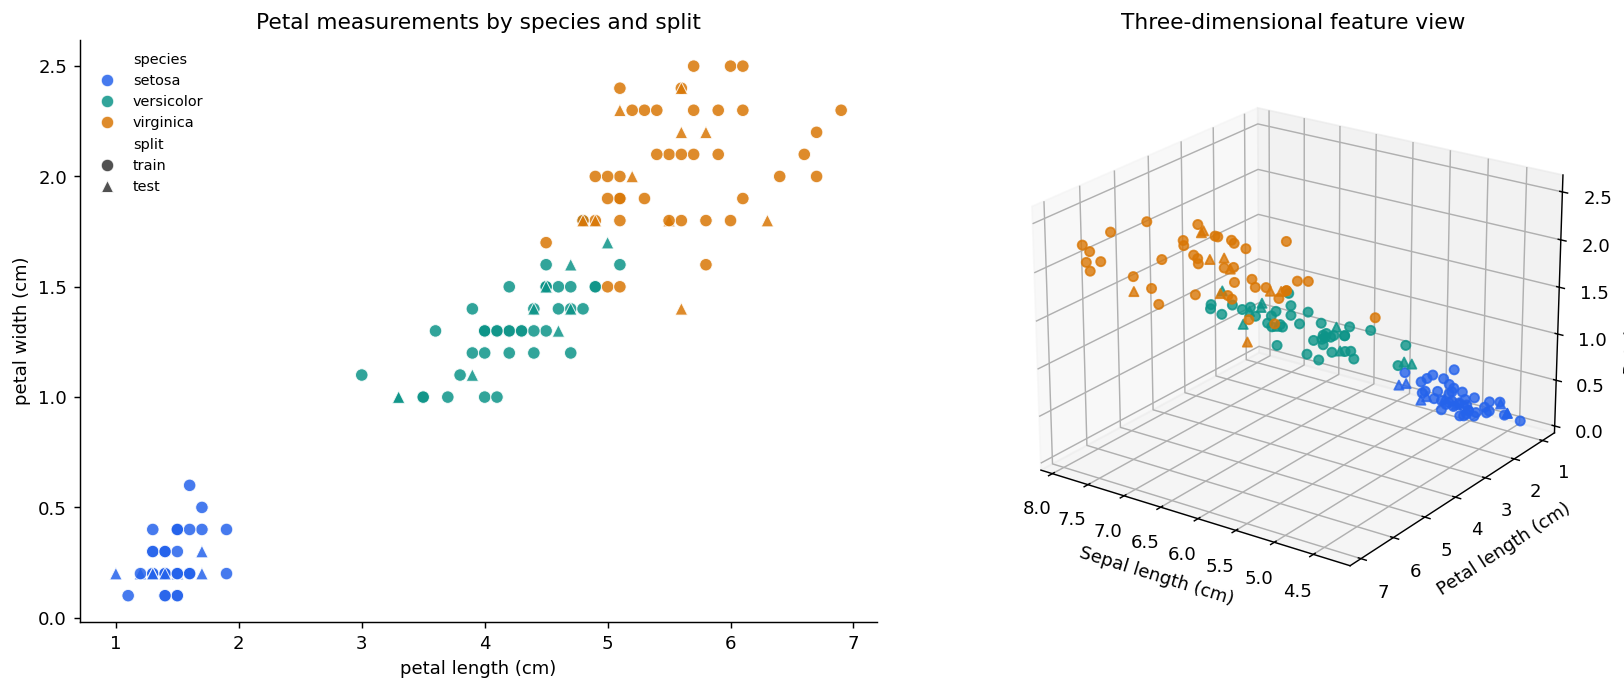

In [12]:
species_colors = {"setosa": "#2563eb", "versicolor": "#0d9488", "virginica": "#d97706"}
fig = plt.figure(figsize=(13, 5.2), layout="constrained")
ax2 = fig.add_subplot(1, 2, 1)
sns.scatterplot(data=iris_all, x="petal length (cm)", y="petal width (cm)",
                hue="species", style="split", palette=species_colors,
                markers={"train": "o", "test": "^"}, s=48, alpha=.85, ax=ax2)
ax2.set_title("Petal measurements by species and split")
ax2.legend(fontsize=8, frameon=False)
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
for species, color in species_colors.items():
    for split, marker in [("train", "o"), ("test", "^")]:
        subset = iris_all[(iris_all.species == species) & (iris_all.split == split)]
        ax3.scatter(subset["sepal length (cm)"], subset["petal length (cm)"],
                    subset["petal width (cm)"], color=color, marker=marker, s=26, alpha=.8)
ax3.set(xlabel="Sepal length (cm)", ylabel="Petal length (cm)",
        zlabel="Petal width (cm)", title="Three-dimensional feature view")
ax3.view_init(elev=22, azim=125)
fig.savefig(HERE / "results/iris_scatter.png", dpi=150)
show_figure(fig)

### Feature correlation heatmap

Pearson correlation is computed for the four continuous measurements only. Numeric species codes, split labels and the discretized feature are excluded because they are not continuous physical measurements.

Petal length–width correlation: 0.9629


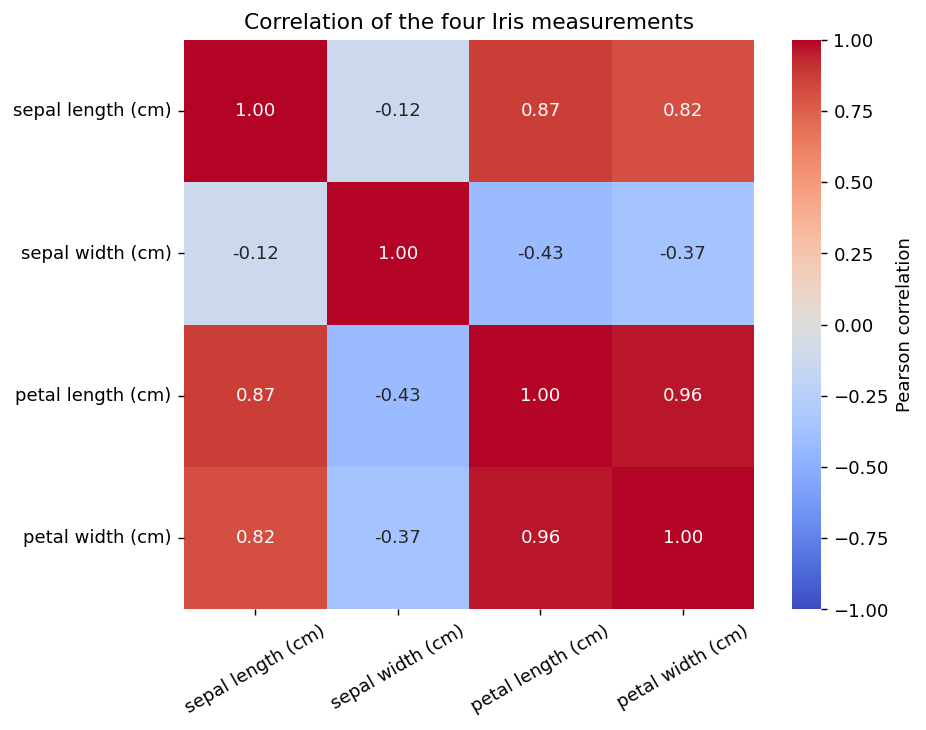

In [13]:
iris_correlation = iris_all[feature_cols].corr()
fig, ax = plt.subplots(figsize=(7.2, 5.5), layout="constrained")
sns.heatmap(iris_correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, ax=ax,
            cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation of the four Iris measurements")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
fig.savefig(HERE / "results/iris_correlation.png", dpi=150)
show_figure(fig)
print("Petal length–width correlation:", round(iris_correlation.loc["petal length (cm)", "petal width (cm)"], 4))

### Feature density: train versus test

Each feature gets its own plot, with training and test KDE curves on the same axes. KDE gives a smoothed density estimate, not a classifier score. The smaller test set can produce less stable curves; visual differences alone do not establish a distribution shift.

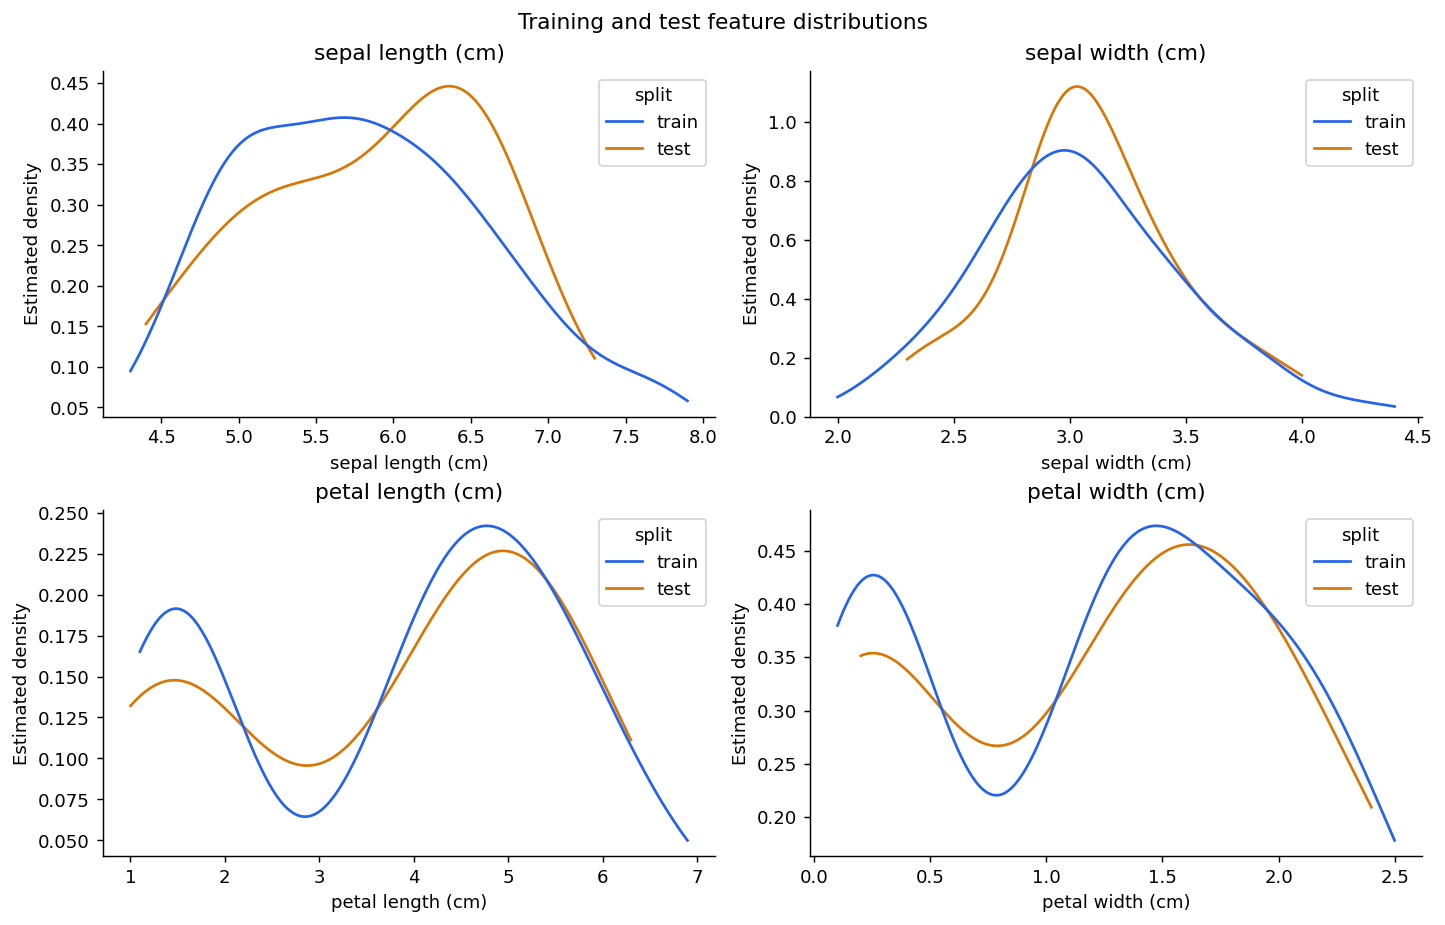

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for feature, ax in zip(feature_cols, axes.flat):
    sns.kdeplot(data=iris_all, x=feature, hue="split", hue_order=["train", "test"],
                common_norm=False, cut=0, bw_adjust=1,
                palette={"train": "#2563eb", "test": "#d97706"}, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel("Estimated density")
fig.suptitle("Training and test feature distributions")
fig.savefig(HERE / "results/iris_densities.png", dpi=150)
show_figure(fig)

## II-c. Discretize one continuous feature

Discretize **sepal length** into `short`, `medium` and `long`. The two thresholds are the 1/3 and 2/3 quantiles of the **training set only**. Fixed thresholds are then applied to both subsets, and the original continuous column is retained.

Intervals are right-closed: a value equal to a threshold belongs to the lower group. Infinite outer bounds ensure that a test observation outside the training range still receives a group. These length groups are an exploratory feature, not flower-species labels.

In [15]:
sepal_feature = "sepal length (cm)"
q_low, q_high = iris_train[sepal_feature].quantile([1/3, 2/3]).to_numpy()
assert q_low < q_high
length_edges = [-np.inf, q_low, q_high, np.inf]
length_labels = ["short", "medium", "long"]
for frame in (iris_train, iris_test, iris_all):
    frame["sepal_length_group"] = pd.cut(
        frame[sepal_feature], bins=length_edges,
        labels=length_labels, right=True, include_lowest=True,
    )
assert iris_all.sepal_length_group.notna().all()
np.testing.assert_array_equal(
    pd.cut(pd.Series([q_low, q_high, q_high + 1e-8]), length_edges, labels=length_labels).astype(str),
    ["short", "medium", "long"],
)
print(f"Training thresholds: short <= {q_low:.3f} cm; medium <= {q_high:.3f} cm; long > {q_high:.3f} cm")
display(iris_all[[sepal_feature, "sepal_length_group", "split"]].head())
display(pd.crosstab(iris_all.sepal_length_group, iris_all.split, dropna=False))
iris_all.to_csv(HERE / "results/iris_data.csv", index=False)

Training thresholds: short <= 5.400 cm; medium <= 6.200 cm; long > 6.200 cm


,sepal length (cm),sepal_length_group,split
sample_id,,,
0,5.1,short,train
1,4.9,short,train
2,4.7,short,train
3,4.6,short,train
4,5.0,short,train


split,test,train
sepal_length_group,,
short,11,41
medium,7,40
long,12,39


## II-d. Descriptive statistics for Setosa

Select the 50 Setosa observations and call `describe()` on their four continuous features. This reports count, mean, sample standard deviation, minimum, quartiles and maximum. Here pandas uses sample standard deviation (`ddof=1`), whereas the signal exercise explicitly used population standard deviation (`ddof=0`).

In [16]:
setosa = iris_all.loc[iris_all.species == "setosa", feature_cols]
setosa_summary = setosa.describe()
assert setosa.shape == (50, 4)
assert setosa_summary.loc["count"].eq(50).all()
np.testing.assert_allclose(setosa_summary.loc["mean"], [5.006, 3.428, 1.462, .246])
setosa_summary.to_csv(HERE / "results/iris_setosa_summary.csv", index_label="statistic")
display(setosa_summary)
print("All Iris checks passed: split sizes, sample identity, class balance, bin boundaries and Setosa statistics.")

All Iris checks passed: split sizes, sample identity, class balance, bin boundaries and Setosa statistics.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,50.00000,50.000000,50.000000,50.000000
mean,5.00600,3.428000,1.462000,0.246000
std,0.35249,0.379064,0.173664,0.105386
min,4.30000,2.300000,1.000000,0.100000
25%,4.80000,3.200000,1.400000,0.200000
50%,5.00000,3.400000,1.500000,0.200000
75%,5.20000,3.675000,1.575000,0.300000
max,5.80000,4.400000,1.900000,0.600000


## Iris findings

- Setosa has much smaller petal measurements and forms a visually distinct group. Versicolor and virginica overlap in the plotted feature views.
- Petal length and width are strongly positively correlated (about 0.963 across the 150 observations). Correlation does not establish a causal relationship.
- The 120/30 split retains the same species balance. The overlaid density curves are an exploratory comparison; the 30-observation test subset is too small for confident conclusions from curve shape alone.
- Setosa mean sepal length/width are **5.006/3.428 cm**, and mean petal length/width are **1.462/0.246 cm**.
- Sepal-length groups are produced without deriving thresholds from the test observations. No classifier is trained or predictive accuracy claimed in this exercise.

# Homework 1 status

The linear algebra, CWRU signal and Iris sections have been implemented and checked. Code and explanations are kept in this notebook; exported figures and tables are in the same homework folder's `results` directory.